# Build graphs from the ingested models

Turns the `ep` schema into the graphs the experiment compares: SQL transforms produce node and edge
tables in `ep_transformed`, those become per-model PyTorch Geometric graphs, and the manifests index
what was written.

The ten configurations are the experiment. Each is a different way of describing the *same* building:
zone or component granularity, homogeneous or heterogeneous, and three ways of carrying weather. The
models never change — only the representation does — so any difference in prediction accuracy is
attributable to the representation.

This notebook holds decisions: which configurations, how many models, whether to rebuild. Mechanism
lives in `beg.pipeline` and `beg.build`.

**What it produces**

```
outputs/pyg_graphs/homo/<Cn_name>/<model_id>.pt
outputs/pyg_graphs/hetero/<Cn_name>/<model_id>.pt
outputs/pyg_graphs/graphs_manifest_homo.parquet
outputs/pyg_graphs/graphs_manifest_hetero.parquet
```

`BEG_03_Datasets` reads the two manifests, so those are the contract with everything downstream.

**Before running**

- `BEG_01_Ingest` must have completed: this reads `ep`, and stops if the shading source is missing.
- The first run is the long one. Transforms take minutes, and building ten configurations over the
  full model set is the longest step in the pipeline. Everything is resumable — an existing `.pt` is
  reused unless you force a rebuild.

**Environment.** `pip install -e ".[notebooks,train,viz]"` installs what this notebook needs, and `pip install -e ".[all]"` what all five need. The first cell checks and prints the command for anything missing; `beg doctor` does the same for every notebook at once.

# Run settings

### Configure the run

**Inputs**: the `ep` schema, `configs/`, and `data/labels.csv`.

**Steps**
1. Choose the configuration set and how many models to build.
2. Set the three rebuild flags. They cascade: rebuilding transforms without rebuilding the
   DataFrames and graphs would leave the later stages reading stale cached output.
3. Resolve every configuration through `beg.config.naming`.

**Outputs**
- `engine`, `CONFIGS`, `LABEL_MODEL_IDS`, `GRAPHS_ROOT` and the settings the later cells read.

**Used functions**
`beg.requirements.check_environment`, `beg.config.naming.resolve`, `beg.config.naming.sort_key`, `beg.settings.output_dir`

In [1]:
from beg.requirements import check_environment

check_environment("BEG_02_Graphs")  # names anything missing, and the pip command that adds it

import warnings
from pathlib import Path

import pandas as pd
from IPython.display import display

# Import-time warnings unrelated to this pipeline (tqdm without ipywidgets, torch.jit)
warnings.filterwarnings("ignore", message=".*IProgress not found.*")
warnings.filterwarnings("ignore", message=".*torch.jit.script.*")

from beg.config.naming import CONFIG_ORDER, resolve, sort_key
from beg.db import get_engine
from beg.settings import data_dir, display_path, output_dir, repo_root

# --- what to build ----------------------------------------------------------
CONFIGS = list(CONFIG_ORDER)      # all ten; narrow to e.g. ["C1", "C3"] while developing
MAX_GRAPHS = None                 # int to cap the models per configuration; None for all

# --- how to build -----------------------------------------------------------
# These cascade. Rebuilding the transforms without also rebuilding the DataFrames
# and the graphs leaves the later stages reading cached output of the old SQL --
# the cache checks whether its output exists, not whether the SQL changed.
REBUILD_TRANSFORMS = False        # re-run the SQL even if the output relations exist
FORCE_REBUILD_DATAFRAMES = False  # re-fetch from the database, ignoring the DataFrame cache
FORCE_REBUILD_PYG_GRAPHS = False  # rewrite every .pt, including those already on disk

TRANSFORM_MODE = "tables"         # "tables" -> ep_transformed; "views" -> ep

CONFIGS_DIR = repo_root() / "configs"
LABELS_CSV = data_dir() / "labels.csv"
GRAPHS_ROOT = output_dir() / "pyg_graphs"
GRAPHS_ROOT.mkdir(parents=True, exist_ok=True)

engine = get_engine()

# Only models with a target are built.
labels_df = pd.read_csv(LABELS_CSV)
LABEL_MODEL_IDS = set(labels_df["building_id"].astype(str).str.strip().str.lower())

CONFIGS = sorted(CONFIGS, key=sort_key)

# Three names per configuration, and they are not interchangeable:
#   id        C5                               what you type here
#   slug      zone_hetero_external_weather     what `configs_summary` and the
#                                              fetched `data` are keyed by
#   full_name C5_zone_hetero_external_weather  the directory and manifest name
# Later cells key by slug, because that is what the pipeline returns.
SLUG_OF = {c: resolve(c).slug for c in CONFIGS}
FULL_NAME_OF = {resolve(c).slug: resolve(c).full_name for c in CONFIGS}

catalogue = pd.DataFrame(
    [
        {
            "id": resolve(c).id,
            "full_name": resolve(c).full_name,
            "level": resolve(c).level,
            "graph_type": resolve(c).graph_type,
            "weather": resolve(c).weather_variant,
            "derived_from": resolve(c).derived_from or "-",
        }
        for c in CONFIGS
    ]
)

print(f"configurations : {len(CONFIGS)}")
print(f"models with a label: {len(LABEL_MODEL_IDS)}" + (f", capped at {MAX_GRAPHS}" if MAX_GRAPHS else ""))
print(f"graphs root    : {display_path(GRAPHS_ROOT)}")
print(f"rebuild        : transforms={REBUILD_TRANSFORMS} dataframes={FORCE_REBUILD_DATAFRAMES} graphs={FORCE_REBUILD_PYG_GRAPHS}")

catalogue

environment ok for BEG_02_Graphs
configurations : 10
models with a label: 13260
graphs root    : outputs/pyg_graphs
rebuild        : transforms=False dataframes=False graphs=False


,id,full_name,level,graph_type,weather,derived_from
0,C1,C1_zone_homo_no_weather,zone,homo,no_weather,-
1,C2,C2_zone_homo_graph_weather,zone,homo,graph_weather,C1
2,C3,C3_zone_hetero_no_weather,zone,hetero,no_weather,-
3,C4,C4_zone_hetero_building_weather,zone,hetero,building_weather,-
4,C5,C5_zone_hetero_external_weather,zone,hetero,external_weather,-
5,C6,C6_component_homo_no_weather,component,homo,no_weather,-
6,C7,C7_component_homo_graph_weather,component,homo,graph_weather,C6
7,C8,C8_component_hetero_no_weather,component,hetero,no_weather,-
8,C9,C9_component_hetero_building_weather,component,hetero,building_weather,-
9,C10,C10_component_hetero_external_weather,component,hetero,external_weather,-


# Transforms and graphs

## Build every configuration, one at a time

Two stages in one pass, per configuration: the SQL transforms produce that
configuration's node and edge relations in `ep_transformed`, those are fetched into
DataFrames, and each model becomes one `.pt` file.

Each configuration's frames are released before the next is read, so memory peaks at about
3.3 GB on the full set. After the first configuration the transforms are cached.

**Two things worth knowing about the transforms**

- *The cache checks existence, not content.* A transform is skipped when its output
  relation is already there, so editing a `.sql` file has no effect until
  `REBUILD_TRANSFORMS = True`. The same is true after an interrupted run, which can leave
  a half-built relation that the check reads as complete.
- *Shading is a precondition.* Several transforms read `ep.surface_shading_metrics`. If it
  is missing or incomplete it is computed first (about twelve minutes on the full set, once),
  and an all-zero table stops the run.

**About the graphs.** An existing `.pt` is reused unless `FORCE_REBUILD_PYG_GRAPHS` is set,
so an interrupted run resumes. Files for models outside this run are removed. Every graph in a
configuration has the same edge-feature width, including models without edges, so batches
collate.

**Outputs**: `.pt` files under `pyg_graphs/{homo,hetero}/`, plus `export`,
`configs_summary` and `model_ids_by_config`.

**Used functions**
`beg.build.export.build_and_export`

In [2]:
import time

from beg.build.export import build_and_export

t0 = time.perf_counter()
export, configs_summary, model_ids_by_config = build_and_export(
    configs=CONFIGS,
    configs_dir=CONFIGS_DIR,
    engine=engine,
    graphs_root=GRAPHS_ROOT,
    keep_model_ids=LABEL_MODEL_IDS,
    max_graphs=MAX_GRAPHS,
    rebuild_transforms=REBUILD_TRANSFORMS,
    transform_mode=TRANSFORM_MODE,
    force_rebuild=FORCE_REBUILD_PYG_GRAPHS,
)
elapsed = time.perf_counter() - t0

written = export["homo"].saved + export["hetero"].saved
reused = export["homo"].skipped + export["hetero"].skipped
print(f"{written} graph(s) written, {reused} reused, in {elapsed/60:.1f} min")

pd.concat([export["homo"].summary(), export["hetero"].summary()], ignore_index=True)

Building configurations: 100%|██████████| 10/10 [00:06<00:00,  1.50config/s]

0 graph(s) written, 106080 reused, in 0.1 min


,config_name,config_full_name,model_ids,saved,skipped_existing,removed_stale,edge_feature_dim
0,zone_homo_no_weather,C1_zone_homo_no_weather,13260,0,13260,0,0
1,component_homo_no_weather,C6_component_homo_no_weather,13260,0,13260,0,0
2,component_hetero_external_weather,C10_component_hetero_external_weather,13260,0,13260,0,9
3,zone_hetero_no_weather,C3_zone_hetero_no_weather,13260,0,13260,0,3
4,zone_hetero_building_weather,C4_zone_hetero_building_weather,13260,0,13260,0,3
5,zone_hetero_external_weather,C5_zone_hetero_external_weather,13260,0,13260,0,4
6,component_hetero_no_weather,C8_component_hetero_no_weather,13260,0,13260,0,7
7,component_hetero_building_weather,C9_component_hetero_building_weather,13260,0,13260,0,7


# Weather variants

## Load and normalise the per-city weather features

C2 and C7 carry the city's weather as a single vector attached to the whole graph (C4 and C9 carry
it in the building node, C5 and C10 as a separate node). They have no configuration file: they
are C1 and C6 with one extra attribute, which `beg.config.naming` records as `derived_from`.

The features come from `ep.weather_city`, one row per model, restricted to the models being built and
z-scored so that no single column dominates by unit alone.

**The normalisation is fitted on every model built, before the train/test split in
`BEG_03_Datasets`**, so test-set weather statistics inform the training features of C2 and C7; see
`docs/limitations.md`.

**Outputs**: `weather`, holding one normalised vector per model.

**Used functions**
`beg.build.weather_vector.load_weather_features`

In [3]:
from beg.build.weather_vector import load_weather_features

base_model_ids = sorted({mid for ids in export["homo"].target_model_ids.values() for mid in ids})
weather = load_weather_features(engine, base_model_ids)

print(f"{len(weather)} of {len(base_model_ids)} model(s) have a weather row.")
display(weather.summary())

weather.describe_columns(8)

13260 of 13260 model(s) have a weather row.


,models_with_weather,feature_columns,normalisation
0,13260,223,z-score over all models built


,column,mean,std
0,latitude,48.824610,5.601725
1,longitude,10.201580,9.746290
2,elevation_m,161.114736,207.840116
3,cdd26_01,0.000000,1.000000
4,cdd26_02,0.000015,0.000614
5,cdd26_03,0.001028,0.018221
6,cdd26_04,0.045453,0.217703
7,cdd26_05,0.880356,1.899775


### Attach the weather vector to the homogeneous graphs

Each base graph is read, given the vector, and written to the derived configuration's directory. A
model with no weather row is skipped.

**Outputs**: `.pt` files under `pyg_graphs/homo/C2_...` and `C7_...`, and `weather_attach`.

**Used functions**
`beg.build.weather_vector.attach_weather_vectors`

In [4]:
from beg.build.weather_vector import attach_weather_vectors

# The configurations something derives from: C1 and C6.
BASE_CONFIGS = [SLUG_OF[c] for c in CONFIGS
                if resolve(c).graph_type == "homo" and not resolve(c).derived_from]

weather_attach = attach_weather_vectors(
    base_configs=BASE_CONFIGS,
    full_name_of=FULL_NAME_OF,
    weather=weather,
    graphs_root=GRAPHS_ROOT,
    force_rebuild=FORCE_REBUILD_PYG_GRAPHS,
)

missing = weather_attach.summary()["missing_weather"].sum() if weather_attach.rows else 0
if missing:
    print(f"WARNING: {missing} graph(s) had no weather row and were skipped.")
print(f"wrote {weather_attach.saved} weather-augmented graph(s)")

weather_attach.summary()

wrote 0 weather-augmented graph(s)


,base_config,weather_config,input_graphs,saved,skipped_existing,missing_weather,removed_stale
0,C1_zone_homo_no_weather,C2_zone_homo_graph_weather,13260,0,13260,0,0
1,C6_component_homo_no_weather,C7_component_homo_graph_weather,13260,0,13260,0,0


# Manifests

## Index what is on disk

The manifests are the contract with `BEG_03_Datasets`. They are built from the graph files on disk,
so they list only graphs that exist.

**Outputs**: `graphs_manifest_homo.parquet` and `graphs_manifest_hetero.parquet`.

**Used functions**
`beg.build.export.write_manifests`, `manifest_summary`

In [5]:
from beg.build.export import manifest_summary, write_manifests

written = write_manifests(GRAPHS_ROOT)
for kind, path in written.items():
    print(f"{kind:7} -> {display_path(path)}")

manifests = manifest_summary(GRAPHS_ROOT)
manifests

homo    -> outputs/pyg_graphs/graphs_manifest_homo.parquet
hetero  -> outputs/pyg_graphs/graphs_manifest_hetero.parquet


,graph_type,config_full_name,graphs,megabytes
0,hetero,C10_component_hetero_external_weather,13260,716.9
1,hetero,C3_zone_hetero_no_weather,13260,123.4
2,hetero,C4_zone_hetero_building_weather,13260,213.7
3,hetero,C5_zone_hetero_external_weather,13260,228.7
4,hetero,C8_component_hetero_no_weather,13260,556.6
5,hetero,C9_component_hetero_building_weather,13260,646.6
6,homo,C1_zone_homo_no_weather,13260,81.4
7,homo,C2_zone_homo_graph_weather,13260,96.5
8,homo,C6_component_homo_no_weather,13260,614.9
9,homo,C7_component_homo_graph_weather,13260,630.0


### Check that the next notebook can run

`BEG_03_Datasets` needs both manifests, one directory per configuration, and a graph count that
matches across configurations, since the comparison is paired over models.

**Outputs**: `readiness`, and a failure if anything downstream would break.

In [6]:
checks = []

for kind, path in written.items():
    checks.append({"check": f"{kind} manifest exists", "ok": path.exists(), "detail": display_path(path)})

expected = {resolve(c).full_name for c in CONFIGS}
found = set(manifests["config_full_name"]) if not manifests.empty else set()
missing_cfg = sorted(expected - found)
checks.append(
    {"check": "every configuration has graphs", "ok": not missing_cfg,
     "detail": "all present" if not missing_cfg else f"missing: {', '.join(missing_cfg)}"}
)

if not manifests.empty:
    counts = manifests.groupby("config_full_name")["graphs"].sum()
    same = counts.nunique() == 1
    checks.append(
        {"check": "graph counts agree across configurations", "ok": bool(same),
         "detail": f"{int(counts.min())}-{int(counts.max())} graphs per configuration"}
    )

readiness = pd.DataFrame(checks)
if not readiness["ok"].all():
    print("NOT READY - resolve the failures above before running BEG_03_Datasets.")
else:
    print("Ready for BEG_03_Datasets.")

readiness

Ready for BEG_03_Datasets.


,check,ok,detail
0,homo manifest exists,True,outputs/pyg_graphs/graphs_manifest_homo.parquet
1,hetero manifest exists,True,outputs/pyg_graphs/graphs_manifest_hetero.parquet
2,every configuration has graphs,True,all present
3,graph counts agree across configurations,True,13260-13260 graphs per configuration


# Inspecting the result

## Draw the distinct configuration topologies

Ten configurations produce six shapes. Weather enters a graph in three ways and only one of them is
visible in a drawing: `external_weather` adds a weather node, while `graph_weather` attaches a vector
to the whole graph and `building_weather` widens the building node's features. So C1/C2, C3/C4,
C6/C7 and C8/C9 each collapse to a single panel.

The panels are read from the exported `.pt` files.

**Inputs**
- Exported graphs under `outputs/pyg_graphs/**`, one per panel
- `FIGURE_MODEL` — the one building drawn in every panel

**Steps**
1. Group the ten configurations by level, graph type, and whether weather is a node of its own.
2. Read one exported graph per group and convert it to NetworkX, keeping the type names.
3. Draw each panel, colouring nodes by type and edges by what they connect.

**Outputs**
- `outputs/figures/configuration_topologies.png`
- `topology_table`, the node and edge count behind every panel

**Used functions**
`distinct_topologies`, `load_topology_panels`, `plot_topologies`

6 distinct topologies from 10 configurations, model Aarhus_0074
figure -> outputs/figures/configuration_topologies.png


,panel,drawn_from,shared_by,nodes,edges
0,C1 / C2,C1,2,4,8
1,C3 / C4,C3,2,5,16
2,C5,C5,1,6,20
3,C6 / C7,C6,2,42,184
4,C8 / C9,C8,2,47,100
5,C10,C10,1,48,134


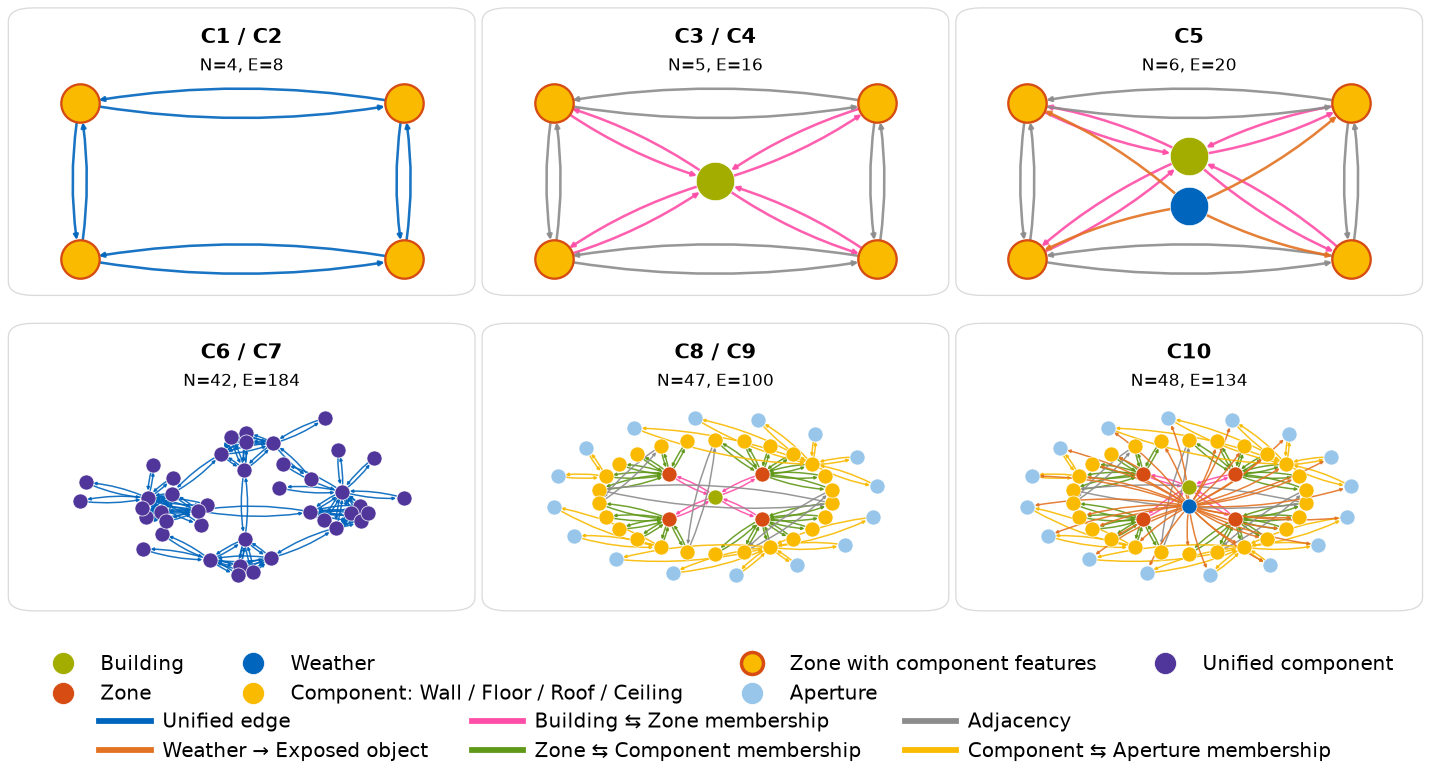

In [7]:
from beg.report.style import show
from beg.report.topology_figure import load_topology_panels, plot_topologies

# Any model works; 2 floors x 2 zones keeps every node legible and shows every edge type
FIGURE_MODEL = "Aarhus_0074"
FIGURE_PATH = output_dir() / "figures" / "configuration_topologies.png"

panels = load_topology_panels(GRAPHS_ROOT, FIGURE_MODEL)
fig = plot_topologies(panels, node_scale=1.0, edge_scale=1.0)

FIGURE_PATH.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURE_PATH, dpi=200, bbox_inches="tight", facecolor="white")

topology_table = pd.DataFrame(
    [
        {
            "panel": p.title,
            "drawn_from": p.representative,
            "shared_by": len(p.config_ids),
            "nodes": p.n_nodes,
            "edges": p.n_edges,
        }
        for p in panels
    ]
)

print(f"{len(panels)} distinct topologies from {len(CONFIGS)} configurations, model {FIGURE_MODEL}")
print(f"figure -> {display_path(FIGURE_PATH)}")

display(topology_table)
show(fig)

## Explore the graphs and the configurations in the browser

Two standalone HTML pages written to `outputs/graph_web/`, opened in the default browser: one to
walk a graph configuration by configuration, one to compare what each configuration actually carries.

The explorer shows each building in 3D beside its graphs, read from its HBJSON when `data/hbjson/`
holds one and rebuilt from the epJSON otherwise.

The graphs are rebuilt from the database, since the pages list feature names and the `.pt` files
store features without them. Only `WEB_APP_MODELS` buildings are fetched, which takes a few seconds.

**Inputs**
- `WEB_APP_MODELS` — how many buildings to include; every one multiplies the page size
- `OPEN_IN_BROWSER` — whether to open the pages once written
- The configuration definitions in `configs/`

**Steps**
1. Fetch a few models' frames for each configuration that has a file.
2. Build one NetworkX graph per configuration per model; C2 and C7 reuse their base.
3. Write one 3D preview page per building into `outputs/graph_web/models/`.
4. Write both pages and open them.

**Outputs**
- `outputs/graph_web/graph_explorer.html` — nested tabs, configuration then model
- `outputs/graph_web/configs_summary.html` — node and edge types per configuration, with columns
- `outputs/graph_web/models/<model>.html` — the 3D previews, sharing one `plotly.min.js`

**Used functions**
`build_pyvis_html_multi`, `build_configs_summary_html`, `write_model_previews`

In [8]:
import contextlib
import io
import webbrowser

from beg.build import build_nx_graph_for_model
from beg.build.export import config_specs, filter_df_by_model_id
from beg.pipeline.dataframes import build_graph_dataframes
from beg.report.configs_summary_html import build_configs_summary_html
from beg.report.graph_viz_web import build_pyvis_html_multi
from beg.report.model_previews import write_model_previews

BUILD_WEB_APPS = True
OPEN_IN_BROWSER = True   # False to write the pages without opening them
WEB_APP_MODELS = 3
WEB_DIR = output_dir() / "graph_web"

if BUILD_WEB_APPS:
    web_out = build_graph_dataframes(
        configs_dir=CONFIGS_DIR,
        config_names=[c for c in CONFIGS if not resolve(c).derived_from],
        engine=engine,
        rebuild_transforms=False,
        max_graphs=WEB_APP_MODELS,
        verbose=False,
    )
    web_data, web_summary = web_out["data"], web_out["configs_summary"]

    web_graphs, web_meta = {}, {}
    for cid in CONFIGS:
        cfg = resolve(cid)
        # C2 and C7 are drawn from their base configurations, C1 and C6
        src = resolve(cfg.derived_from) if cfg.derived_from else cfg
        specs = config_specs(web_summary, src.slug)
        edge_specs = {str(e["edge_src"]): e for e in specs["edges_list"] if e.get("edge_src")}
        nodes = web_data[src.slug].get("nodes") or {}
        edges = web_data[src.slug].get("edges") or {}

        web_graphs[cfg.full_name] = {
            str(mid): build_nx_graph_for_model(
                src.slug,
                str(mid),
                {t: filter_df_by_model_id(df, mid) for t, df in nodes.items()},
                {t: filter_df_by_model_id(df, mid) for t, df in edges.items()},
                specs["node_tables"],
                edge_specs=edge_specs,
            ).G
            for mid in web_data[src.slug].get("model_ids") or []
        }
        web_meta[cfg.full_name] = {
            "id": cfg.id,
            "type": cfg.graph_type,
            "weather": cfg.weather_variant,
            "description": (
                f"graph-level weather vector attached to {cfg.derived_from} at export"
                if cfg.derived_from
                else ""
            ),
            "edges": specs["edges_list"],
        }

    WEB_DIR.mkdir(parents=True, exist_ok=True)

    # One 3D page per building; without the viz extra the explorer is written without them
    preview_urls, preview_hint = {}, ""
    try:
        previews = write_model_previews(
            sorted({mid for graphs in web_graphs.values() for mid in graphs}),
            WEB_DIR / "models",
            relative_to=WEB_DIR,
        )
        preview_urls = previews.urls
        for mid, reason in previews.failed.items():
            print(f"no 3D preview for {mid}: {reason}")
    except ImportError as exc:
        print(f"3D previews skipped. {exc}")
        preview_hint = ('3D previews need the viz extra: pip install -e ".[viz]", '
                        "then restart the kernel and re-run this cell of BEG_02_Graphs.")

    # The builders print absolute paths; keep them out of the stored output
    with contextlib.redirect_stdout(io.StringIO()):
        explorer_path = Path(
            build_pyvis_html_multi(
                web_graphs,
                out_html=str(WEB_DIR / "graph_explorer.html"),
                config_meta=web_meta,
                model_preview_urls=preview_urls,
                model_preview_hint=preview_hint,
            )
        )
        summary_path = Path(
            build_configs_summary_html(
                web_graphs,
                CONFIGS_DIR,
                list(web_graphs),
                WEB_DIR / "configs_summary.html",
                config_metadata_override=web_meta,
            )
        )

    # Opens in the default browser
    for path in (explorer_path, summary_path):
        print(f"{display_path(path):<44} {path.stat().st_size / 1e6:5.1f} MB")
        if OPEN_IN_BROWSER:
            webbrowser.open(path.resolve().as_uri())
else:
    print("Web apps disabled - set BUILD_WEB_APPS = True to write them.")

outputs/graph_web/graph_explorer.html          8.1 MB
outputs/graph_web/configs_summary.html         0.7 MB


---

**Next:** `BEG_03_Datasets` reads the two manifests, joins the graphs to `labels.csv`, applies the
fixed split and writes one `training_ready.pt` per configuration.